# Nova-ST - Exp65-sampleSPC014

## Import packages

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import harpy as hp
import spatialdata as sd
import pandas as pd
import numpy as np
import dask as da
import os
import gc
import geopandas as gpd
import matplotlib
from matplotlib import pyplot as plt
import seaborn as sns
import h5py
import json
import gc
import glob

from dask_image.imread import imread
import spatialdata_plot

from spatialdata.transformations import get_transformation, remove_transformation, set_transformation

c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\xarray_schema\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [ ]:
import sys
sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath(''))))
from utils.in_tissue import add_in_tissue, assign_region
from utils.plotting import best_datatree_scale, rel_fontsize
from utils.qc import qc_metrics
from _novast import novast

## Create sdata

In [ ]:
# path_novascope = f"/data/groups/technologies/spatial.catalyst/Projects/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/{dataset_id}/NovaScope/novascope_output"
path_novascope = f'E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/{dataset_id}/NovaScope/novascope_output'
dataset_id = "Exp65-sampleSPC014"
seq1st_id = "NovaSeq6000_20241107"
chip_id = "03D1"
path_img = f'E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/{dataset_id}/BigWarp/warped.tif'
output_path = f'E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/{dataset_id}/harpy/sdata.zarr'

pipeline_name = 'NovaScope'
species = 'mouse'
tissue_annotation_file = f'E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/{dataset_id}/BigWarp/tissue_warped.geojson'

In [ ]:
# sdata = sd.read_zarr(output_path)

version mismatch: detected: RasterFormatV02, requested: FormatV04
c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\zarr\creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


In [44]:
sdata = novast(
    path = path_novascope,
    dataset_id = dataset_id,
    seq1st_id = seq1st_id,
    chip_id = chip_id,
    path_img = path_img,
    output = output_path
)
sdata

2025-12-22 11:25:00,555 - harpy.io._spatial_data - WARNING - dims parameter is equal to ['c', 'y', 'x'], but will be ignored when reading in images from a file


INFO     The Zarr backing store has been changed from None the new file path:                                      
         E:\2024-07-UTBenchmark-SpC\data\processed\Nova-ST\Exp65-sampleSPC014\harpy\sdata.zarr                     


c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\zarr\creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
2025-12-22 11:25:04,364 - harpy.image._manager - INFO - Writing results to layer 'Exp65-sampleSPC014_he'
version mismatch: detected: RasterFormatV02, requested: FormatV04
c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\zarr\creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


MemoryError: Unable to allocate 179. MiB for an array with shape (23468345,) and data type int64

In [ ]:
sdata

In [ ]:
get_transformation(sdata.images[f"{dataset_id}_he"], get_all=True),

In [ ]:
# Create square grids
# shape = (sdata.images[HE_image]['scale0']['image'].shape[1], sdata.images[HE_image]['scale0']['image'].shape[2])
# levels = [10]

# for level in levels:
#     sdata = hp.im.add_grid_labels_layer(
#         sdata, 
#         shape=shape, 
#         size=level, # level names refer to the side length of the square
#         output_shapes_layer=f"shapes_spots_{level}", 
#         output_labels_layer=f"labels_spots_{level}", 
#         grid_type='hexagon', 
#         offset=(0, 0), 
#         chunks=1024, 
#         client=None, 
#         transformations=None, 
#         scale_factors=(2, 2, 2, 2),
#         overwrite=True
#     )
    
#     sdata = hp.tb.allocate(
#         sdata=sdata,
#         labels_layer=f"labels_spots_{level}",
#         points_layer="transcripts",
#         output_layer=f"table_{level}",
#         update_shapes_layers=False,
#         overwrite=True,
#     )
    
#     sdata = qc_metrics(
#         sdata,
#         f"table_{level}",
#         species
#     )

sdata

INFO     The Zarr backing store has been changed from None the new file path:                                      
         E:\2024-07-UTBenchmark-SpC\data\processed\Nova-ST\Exp65-sampleSPC014\harpy\sdata.zarr                     


c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\zarr\creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
2025-12-01 10:45:25,986 - harpy.image._manager - INFO - Writing results to layer 'HE'
version mismatch: detected: RasterFormatV02, requested: FormatV04
c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\zarr\creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
c:\Users\julien.mortier\conda-envs\harpy_17102025\lib\site-packages\dask\dataframe\io\csv.py:555: UserWarning: Warning gzip compression does not support breaking apart files
Please ensure that each individual file can fit in memory and
use the keyword ``blocksize=None to remove this message``
Setting ``blocksize=None``
  warn(
2025-12-01 10:45:28,464 - harpy.io._transcripts - INFO - Transform matrix used:
 [[0.001 

SpatialData object, with associated Zarr store: E:\2024-07-UTBenchmark-SpC\data\processed\Nova-ST\Exp65-sampleSPC014\harpy\sdata.zarr
├── Images
│     └── 'HE': DataTree[cyx] (3, 6923, 11547), (3, 3461, 5773), (3, 1730, 2886), (3, 865, 1443), (3, 432, 721)
├── Labels
│     └── 'labels_spots_10': DataTree[yx] (6923, 11547), (3461, 5773), (1730, 2886), (865, 1443), (432, 721)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 3) (2D points)
├── Shapes
│     └── 'shapes_spots_10': GeoDataFrame shape: (307026, 1) (2D shapes)
└── Tables
      └── 'table_10': AnnData (254737, 20826)
with coordinate systems:
    ▸ 'global', with elements:
        HE (Images), labels_spots_10 (Labels), transcripts (Points), shapes_spots_10 (Shapes)

## Specify plotting parameters

In [23]:
DPI = 200
MAX_DIM_FOR_PLOTS = 10000

HE_image = 'HE'

best_scale = best_datatree_scale(sdata[HE_image], MAX_DIM_FOR_PLOTS)
print(f'best scale: {best_scale}')

figsize_factor = DPI
figsize = (sdata.images[HE_image][best_scale]['image'].shape[2]/figsize_factor, sdata.images[HE_image][best_scale]['image'].shape[1]/figsize_factor)
print(f'figsize: {figsize}')

plots_path = os.path.join(os.path.dirname(output_path), 'plots')
os.makedirs(plots_path, exist_ok=True)
print(f'plots_path: {plots_path}')

best scale: scale1
figsize: (28.865, 17.305)
plots_path: E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/Exp65-sampleSPC014/harpy\plots


## Plot H&E

In [ ]:
fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

title = "H&E"

sdata.pl.render_images(
    element=HE_image, scale=best_scale
).pl.show(
    title=title,
    figsize=figsize,
    colorbar=False,
    dpi=DPI,
    ax=ax,
)

ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

save_path = os.path.join(plots_path, 'HE.png')
fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

plt.close(fig)

print("Plot saved at:", save_path)

## Plot hexagonal grids

In [ ]:
for level in [10, 20, 40, 100]:  
    fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

    title = f"Hexagonal grid - {level}"

    sdata.pl.render_images(
        element=HE_image, scale=best_scale
    ).pl.render_labels(
        element=f"labels_spots_{level}", fill_alpha=0.1, contour_px=5, outline_alpha=1
    ).pl.show(
        title=title,
        figsize=figsize,
        colorbar=False,
        dpi=DPI,
        ax=ax,
    )
    
    ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
    ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
    ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
    ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

    save_path = os.path.join(plots_path, f'hexagonal_grid_{level}.png')
    fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

    plt.close(fig)

    print("Plot saved at:", save_path)

## Plot QC metrics

In [ ]:
# Plot QC metrics
for level in levels:
    for qc_metric in ['n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'total_counts_mt', 'pct_counts_mt']:
        values = sdata.tables[f"table_{level}"].obs[qc_metric].to_numpy()
        vmin, vmax = np.percentile(values, [1, 99])
        norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)
        
        fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

        title = f"scanpy - {qc_metric}"

        sdata.pl.render_images(
            element=HE_image, scale=best_scale
        ).pl.render_labels(
            element=f"labels_spots_{level}", fill_alpha=1, contour_px=5, outline_alpha=0, color=qc_metric, scale=best_scale, table_name=f"table_{level}", cmap="viridis", norm=norm
        ).pl.show(
            title=title,
            figsize=figsize,
            colorbar=True,
            dpi=DPI,
            ax=ax,
        )

        ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
        ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
        ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
        ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

        cbar = fig.axes[-1]
        cbar.set_ylabel(qc_metric, rotation=270, labelpad=rel_fontsize(fig, 0.025), fontsize = rel_fontsize(fig, 0.02))
        cbar.tick_params(axis="y", which="both", labelsize=rel_fontsize(fig, 0.015))

        save_path = os.path.join(plots_path, f'scanpy_{qc_metric}_{level}.png')
        fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

        plt.close(fig)

        print("Plot saved at:", save_path)

## Plot transcript density

In [ ]:
sdata = hp.im.transcript_density(
    sdata,
    img_layer=HE_image,
    points_layer='transcripts',
    output_layer='transcript_density',
    overwrite=True
)

save_path = os.path.join(plots_path, "transcript_density.png")

hp.pl.transcript_density(
    sdata,
    img_layer=[HE_image, "transcript_density"],
    channel=0,
    output=save_path
)

print("Plot saved at:", save_path)

## Calculate pixel size

In [18]:
microns_per_pixel = 1
print(f"Pixel size: {microns_per_pixel:.3f} µm")

Pixel size: 1.000 µm


## Create bounding box for total capture area

In [24]:
# Add bounding box for total capture area
import shapely

geoms = sdata.shapes["shapes_spots_10"].geometry
bbox = shapely.MultiPolygon(list(geoms)).minimum_rotated_rectangle

sdata = hp.sh.add_shapes_layer(
    sdata,
    input = gpd.GeoDataFrame(geometry=[bbox]),
    output_layer = f'{dataset_id}_capture_area',
    transformations = get_transformation(sdata.shapes['shapes_spots_10'], get_all=True),
    overwrite = True,
)

In [ ]:
# Export bbox GeoJSON
sdata.shapes[f'{dataset_id}_capture_area'].to_file(os.path.join(os.path.dirname(output_path), f'{dataset_id}_capture_area.geojson'), driver="GeoJSON")

In [ ]:
# Check capture area bbox
fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

title = "Capture area bounding box"

sdata.pl.render_images(
    element=HE_image, scale=best_scale
).pl.render_shapes(
    element="shapes_spots_10", color='black', fill_alpha=0.5, outline_width=rel_fontsize(fig, 0.0012), outline_alpha=1, outline_color='black'
).pl.render_shapes(
    element=f'{dataset_id}_capture_area', color='#1f77b4', fill_alpha=0.1, outline_width=rel_fontsize(fig, 0.002), outline_alpha=1, outline_color='red'
).pl.show(
    title=title,
    figsize=figsize,
    colorbar=False,
    dpi=DPI,
    ax=ax,
    pad_extent=rel_fontsize(fig, 0.03)
)

ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

save_path = os.path.join(plots_path, 'capture_area_bbox.png')
fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

plt.close(fig)

print("Plot saved at:", save_path)

In [25]:
# Area of capture area in mm²
gdf = sdata.shapes[f'{dataset_id}_capture_area']
capture_area = (gdf.geometry.area.sum() * microns_per_pixel**2) / 1000000
print(f"Area of capture area: {capture_area:.2f} mm²")

Area of capture area: 79.89 mm²


In [26]:
from math import dist
coords = list(bbox.exterior.coords)

# Compute lengths of bbox
side1 = dist(coords[0], coords[1]) * microns_per_pixel / 10000
side2 = dist(coords[1], coords[2]) * microns_per_pixel / 10000

print(f"Dimensions of capture area bbox: {side1:.2f} cm x {side2:.2f} cm")

Dimensions of capture area bbox: 0.69 cm x 1.15 cm


## Add tissue annotation

In [27]:
# Add tissue annotation as shapes layer and as labels layer
gdf = gpd.read_file(tissue_annotation_file)
gdf = gdf.explode(index_parts=False) # This avoid problems with MultiPolygon geometries
gdf.index = gdf.index + 1 # Index 0 is not allowed

sdata = hp.sh.add_shapes_layer(
    sdata,
    input = gdf,
    output_layer = f'{dataset_id}_tissue',
    overwrite = True,
)

sdata = hp.im.rasterize(
    sdata,
    shapes_layer = f'{dataset_id}_tissue',
    output_layer = f'{dataset_id}_tissue_mask',
    chunks = 1024,
    overwrite = True,
)

2025-12-01 10:53:39,916 - harpy.image._manager - INFO - Writing results to layer 'Exp65-sampleSPC014_tissue_mask'


In [28]:
# Check tissue annotation
fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

title = "Tissue annotation"

sdata.pl.render_images(
    element=HE_image, scale=best_scale
).pl.render_shapes(
    element=f'{dataset_id}_tissue', color='#1f77b4', fill_alpha=0.3, outline_width=rel_fontsize(fig, 0.002), outline_alpha=1, outline_color='red'
).pl.show(
    title=title,
    figsize=figsize,
    colorbar=False,
    dpi=DPI,
    ax=ax,
    pad_extent=rel_fontsize(fig, 0.02)
)

ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

save_path = os.path.join(plots_path, 'qupath_tissue_annotation.png')
fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

plt.close(fig)

print("Plot saved at:", save_path)

INFO     Value for parameter 'color' appears to be a color, using it as such.                                      
Plot saved at: E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/Exp65-sampleSPC014/harpy\plots\qupath_tissue_annotation.png


In [29]:
# Determine which spots are in tissue annotation
for level in levels:
    gc.collect()
    sdata = add_in_tissue(
        sdata, 
        table_layer = f"table_{level}", 
        tissue_mask = sdata.labels[f'{dataset_id}_tissue_mask'].compute().data
    )

2025-12-01 10:54:11,934 - harpy.utils._io - WARNING - layer with name 'table_10' already exists. Overwriting...


In [30]:
# Check spots in tissue
for level in levels:
    gc.collect()
    fig, ax = plt.subplots(figsize=figsize, dpi=DPI)

    title = "Tissue annotation spots"

    sdata.pl.render_images(
        element=HE_image, scale=best_scale
    ).pl.render_labels(
        element=f"labels_spots_{level}", fill_alpha=0.5, contour_px=5, outline_alpha=0, color='in_tissue_annotation', table_layer=f"table_{level}", scale=best_scale
    ).pl.show(
        title=title,
        figsize=figsize,
        colorbar=False,
        dpi=DPI,
        ax=ax,
        pad_extent=rel_fontsize(fig, 0.02)
    )

    ax.set_title(title, fontsize=rel_fontsize(fig, 0.02))
    ax.set_xlabel("x", fontsize=rel_fontsize(fig, 0.02))
    ax.set_ylabel("y", fontsize=rel_fontsize(fig, 0.02))
    ax.tick_params(axis="both", which="both", labelsize=rel_fontsize(fig, 0.015))

    save_path = os.path.join(plots_path, f'qupath_annotation_spots_{level}.png')
    fig.savefig(save_path, bbox_inches="tight", pad_inches=max(fig.get_size_inches())/100, facecolor="white", transparent=False)

    plt.close(fig)

    print("Plot saved at:", save_path)

Plot saved at: E:/2024-07-UTBenchmark-SpC/data/processed/Nova-ST/Exp65-sampleSPC014/harpy\plots\qupath_annotation_spots_10.png


#### fastq2sbcd

In [ ]:
sbcds_manifest = pd.read_csv(os.path.join(path_novascope, f'seq1st/{seq1st_id}/sbcds/{seq1st_id}/manifest.tsv'), delimiter='\t')
sbcds_manifest
# NOTE: sbcds contains the information for ALL chips that were cut from this flowcell (not just the one used for this sample).

,id,filepath,barcodes,matches,mismatches,xmin,xmax,ymin,ymax
0,1_1101,1_1101.sbcds.sorted.tsv.gz,3441661,3377626,64035,1136,32931,1016,37059
1,1_1102,1_1102.sbcds.sorted.tsv.gz,3439440,3377026,62414,1136,32931,1016,37059
2,1_1103,1_1103.sbcds.sorted.tsv.gz,3440741,3377136,63605,1127,32922,1016,37059
3,1_1104,1_1104.sbcds.sorted.tsv.gz,3441762,3378802,62960,1136,32931,1016,37059
4,1_1105,1_1105.sbcds.sorted.tsv.gz,3441644,3375816,65828,1118,32922,1016,37059
...,...,...,...,...,...,...,...,...,...
3738,4_2674,4_2674.sbcds.sorted.tsv.gz,3423140,3357938,65202,1072,32859,1031,37059
3739,4_2675,4_2675.sbcds.sorted.tsv.gz,3414367,3347807,66560,1063,32859,1031,37059
3740,4_2676,4_2676.sbcds.sorted.tsv.gz,3414774,3355234,59540,1054,32850,1047,37059
3741,4_2677,4_2677.sbcds.sorted.tsv.gz,3419366,3355813,63553,1054,32841,1047,37059


In [ ]:
print('Number of tiles:', sbcds_manifest['id'].nunique())
print(f"Sum of all spatial barcodes: {sbcds_manifest['barcodes'].sum():,}")
print(f"Sum of all spatial barcodes (matches): {sbcds_manifest['matches'].sum():,}")
print(f"Sum of all spatial barcodes (mismatches): {sbcds_manifest['mismatches'].sum():,}") 

Number of tiles: 3743
Sum of all spatial barcodes: 12,827,831,696
Sum of all spatial barcodes (matches): 12,588,709,400
Sum of all spatial barcodes (mismatches): 239,122,296


#### sbcds2chip

In [ ]:
nbcds_manifest = pd.read_csv(os.path.join(path_novascope, f'seq1st/{seq1st_id}/nbcds/{chip_id}/manifest.tsv'), delimiter='\t')
nbcds_manifest
# NOTE: nbcds contains only the information for the chip of this particular sample.

,id,filepath,barcodes,matches,mismatches,xmin,xmax,ymin,ymax
0,1_1,1_1.sbcds.sorted.tsv.gz,117071907,117071907,0,0,11545568,0,6921220


In [ ]:
print(f"All spatial barcodes: {nbcds_manifest['barcodes'][0]:,}")
print(f"All spatial barcodes (matches): {nbcds_manifest['matches'][0]:,}")
print(f"All spatial barcodes (mismatches): {nbcds_manifest['mismatches'][0]:,}")
print(f"Coordinates (xmin, xmax, ymin, ymax): ({nbcds_manifest['xmin'][0]}, {nbcds_manifest['xmax'][0]}, {nbcds_manifest['ymin'][0]}, {nbcds_manifest['ymax'][0]})")

All spatial barcodes: 117,071,907
All spatial barcodes (matches): 117,071,907
All spatial barcodes (mismatches): 0
Coordinates (xmin, xmax, ymin, ymax): (0, 11545568, 0, 6921220)


In [ ]:
nbcds_sorted = pd.read_csv(os.path.join(path_novascope, f'seq1st/{seq1st}/nbcds/{chip_id}/1_1.sbcds.sorted.tsv.gz'), delimiter='\t', header=None, names=['barcode', 'lane_id', 'tile_id', 'x', 'y', 'count'])
nbcds_sorted
# This file maps spatial barcodes to global chip coordinates, with duplicate barcodes removed.

,barcode,lane_id,tile_id,x,y,count
0,AAAAAAAAAAAAAAAAACTGGGAAGGGTTATA,1,1,93662,2391507,1
1,AAAAAAAAAAAAAAAACGCGACTCTGGAAATT,1,1,2686233,4096979,1
2,AAAAAAAAAAAACACGACCGCATCTGGCGTTC,1,1,1061381,494606,1
3,AAAAAAAAAACGCGACCGGGGGGGGGCTTTAG,1,1,10951074,2969446,1
4,AAAAAAAAAACGGCGGGGTAGGAAATATGTGA,1,1,1578212,2597787,1
...,...,...,...,...,...,...
117071902,TTTTTTTTTTTTTTTTTTTTTTTTACTCCCCC,1,1,1707280,5342451,9
117071903,TTTTTTTTTTTTTTTTTTTTTTTTGGGGGCCA,1,1,9687621,2502838,8
117071904,TTTTTTTTTTTTTTTTTTTTTTTTTATTTTTT,1,1,10517958,2029621,9
117071905,TTTTTTTTTTTTTTTTTTTTTTTTTCAAAACA,1,1,10344267,6492626,8


In [ ]:
print(f"Number of unique spatial barcodes in capture area: {nbcds_sorted['barcode'].nunique():,}")
print(f"Length of spatial barcode: {len(nbcds_sorted['barcode'][0])} bp")
print(f"Number of lanes: {nbcds_sorted['lane_id'].nunique()}") # This probably does not accurately reflect the number of lanes
print(f"Number of tiles: {nbcds_sorted['tile_id'].nunique()}") # This clearly does not accurately reflect the number of tiles
print(f"Coordinates (xmin, xmax, ymin, ymax): ({nbcds_sorted['x'].min()}, {nbcds_sorted['x'].max()}, {nbcds_sorted['y'].min()}, {nbcds_sorted['y'].max()})")
print(f"Number of unique XY coordinates: {nbcds_sorted[['x', 'y']].drop_duplicates().shape[0]:,}")

Number of unique spatial barcodes in capture area: 117,071,907
Length of spatial barcode: 32 bp
Number of lanes: 1
Number of tiles: 1
Coordinates (xmin, xmax, ymin, ymax): (0, 11545568, 0, 6921220)
Number of unique XY coordinates: 117,071,907


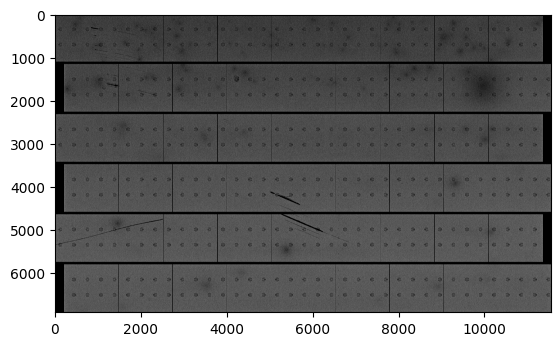

In [ ]:
# Plot sbcd image
from skimage import io
img = io.imread(os.path.join(path_novascope, "seq1st/NovaSeq6000_20241107/nbcds/03D1/1_1.sbcds.sorted.png"))
plt.imshow(img, cmap='grey') # We can count 54 tiles (6 rows x 9 tiles)

In [37]:
# Total number of spots in tissue
tissue_mask = sdata.labels[f'{dataset_id}_tissue_mask'].compute().data
mask_shape = tissue_mask.shape

nbcds_sorted["in_tissue_annotation"] = nbcds_sorted.apply(
    lambda row: assign_region((row["x"]/1000, row["y"]/1000), tissue_mask, mask_shape), axis=1
)

total_n_spots_in_tissue = len(nbcds_sorted[nbcds_sorted['in_tissue_annotation'] == 1])

print(f"Total number of spots in tissue: {total_n_spots_in_tissue}")

Total number of spots in tissue: 30648237


In [ ]:
# Total number of spots in table
n_spots = len(sdata.tables['table_1'].obs)
print(f"Number of spots in table: {n_spots}")

In [ ]:
# Number of spots in tissue (in table)
n_spots_in_tissue = len(sdata.tables['table_1'][sdata.tables['table_1'].obs['in_tissue_annotation'] == 1].obs)
print(f"Number of spots in tissue: {n_spots_in_tissue}")

In [ ]:
# Save barcodes
with open(os.path.join(os.path.dirname(output_path), "all_barcodes.txt"), "w") as f:
    for item in nbcds_sorted['barcode']:
        f.write(f"{item}\n")
        
with open(os.path.join(os.path.dirname(output_path), "barcodes_in_tissue.txt"), "w") as f:
    for item in nbcds_sorted[nbcds_sorted['in_tissue_annotation'] == 1]['barcode']:
        f.write(f"{item}\n")      

In [38]:
# Area of tissue annotation that overlaps with capture area in mm²
tissue_gdf = sdata.shapes[f"{dataset_id}_tissue"].unary_union
capture_gdf = sdata.shapes[f"{dataset_id}_capture_area"].unary_union

overlap_geom = tissue_gdf.intersection(capture_gdf)

overlap_area_mm2 = (overlap_geom.area * microns_per_pixel**2) / 1000000

print(f"Capture area covered by tissue: {overlap_area_mm2:.2f} mm²")

Capture area covered by tissue: 20.27 mm²


In [ ]:
# TODO: Use original H&E. 
# TODO: Read in transcript coordinates without decreasing the resolution. Convert to H&E coordinate space.
# TODO: Potentially use affine transformation to register things in sdata.

In [ ]:
# TODO: Calculate the total number of spots (sequenced or not) on a chip. We might be able to deduce this from the number of tiles and info in the paper.

In [16]:
well_to_well = 625
hexagon_area = 338291.1734
capture_area = (nbcds_sorted['x'].max() - nbcds_sorted['x'].min()) * (nbcds_sorted['y'].max() - nbcds_sorted['y'].min())
print(f"Maximum number of wells: {capture_area / hexagon_area:,.0f}")
# NOTE: This is the theoretical maximum if there would be full coverage without any empty space.

Maximum number of wells: 236,214,901


## Capture effeciency metrics

In [ ]:
# TODO: Do we need to subset the transcripts to the actual good ones? Or has this already been done?

#### smatch

In [ ]:
sum_reads = 0
sum_mismatches = 0
sum_matches = 0

for summary in glob.glob(os.path.join(path_novascope, f"match/{seq1st_id}/{chip_id}/**/*.summary.tsv"), recursive=True):
    df = pd.read_csv(summary, delimiter='\t', index_col='Type')
    sum_reads += df.at['Total', 'Reads']
    sum_mismatches += df.at['Miss', 'Reads']
    sum_matches += df.at['Match', 'Reads']

print(f"Sum of all reads: {sum_reads:,}")
print(f"Sum of all mismatches: {sum_mismatches:,} ({(sum_mismatches/sum_reads)*100:.1f} %)")
print(f"Sum of all matches: {sum_matches:,} ({(sum_matches/sum_reads)*100:.1f} %)") # These reads are used for the `align` step

# Total: All reads in the 2nd-seq FASTQ file.
# Miss: Reads that do not contain matching spatial barcodes.
# Match: Reads that match with a spatial barcode.
# Unique: Unique spatial barcodes that has matches.
# Dup(Exact): Duplicate barcodes calculated as Match - Unique.

Sum of all reads: 320,016,940
Sum of all mismatches: 178,588,952 (55.8 %)
Sum of all matches: 141,427,988 (44.2 %)


In [ ]:
unique = set()
unique_xy = set()
sum_count = 0
sum_mismatches = 0

for path in glob.glob(os.path.join(path_novascope, f"match/{seq1st_id}/{chip_id}/**/*.match.sorted.uniq.tsv.gz")):
    for chunk in pd.read_csv(path, sep="\t", header=None, names=['barcode', 'lane_id', 'tile_id', 'x', 'y', 'mismatches', 'count'], usecols=[0, 3, 4, 5, 6], chunksize=500000):
        unique.update(chunk['barcode'])
        unique_xy.update(zip(chunk['x'], chunk['y']))
        sum_count += chunk['count'].sum()
        sum_mismatches += chunk['mismatches'].sum()

print(f"Number of unique spatial barcodes: {len(unique):,}")
print(f"Number of unique XY coordinates: {len(unique_xy):,}")
print(f"Sum of spatial barcode counts (i.e. number of reads containing a valid spatial barcode): {sum_count:,}") # These reads are used for the `align` step
print(f"Sum of mismatches across unique spatial barcodes: {sum_mismatches:,}")

Number of unique spatial barcodes: 30,952,152
Number of unique XY coordinates: 30,952,152
Sum of spatial barcode counts (i.e. number of reads containing a valid spatial barcode): 141,427,988
Sum of mismatches across unique spatial barcodes: 178,809,583


#### align

In [1]:
# STARsolo barcode statistics
bc_stats = {}
with open(os.path.join(path_novascope, f"align/{seq1st_id}/{chip_id}/{dataset_id}/bam/sttoolsSolo.out/Barcodes.stats")) as f:
    for line in f:
        line = line.strip().split()
        bc_stats[line[0]] = int(line[1])
        
total = sum(bc_stats.values())

print(f"noNoAdapter: {bc_stats['noNoAdapter']:,} ({bc_stats['noNoAdapter'] / total * 100:.1f}%)",
    " -  Number of reads without an adapter")
print(f"noNoUMI: {bc_stats['noNoUMI']:,} ({bc_stats['noNoUMI'] / total * 100:.1f}%)",
    " -  Number of reads not associated with a valid UMI")
print(f"noNoCB: {bc_stats['noNoCB']:,} ({bc_stats['noNoCB'] / total * 100:.1f}%)",
    " -  Number of reads not associated with a valid spatial barcode")
print(f"noNinCB: {bc_stats['noNinCB']:,} ({bc_stats['noNinCB'] / total * 100:.1f}%)",
    " -  Number of reads with too many Ns in the spatial barcode")
print(f"noNinUMI: {bc_stats['noNinUMI']:,} ({bc_stats['noNinUMI'] / total * 100:.1f}%)",
    " -  Number of reads with too many Ns in the UMI")
print(f"noUMIhomopolymer: {bc_stats['noUMIhomopolymer']:,} ({bc_stats['noUMIhomopolymer'] / total * 100:.1f}%)",
    " -  Number of reads that have a homopolymeric UMI")
print(f"noNoWLmatch: {bc_stats['noNoWLmatch']:,} ({bc_stats['noNoWLmatch'] / total * 100:.1f}%)",
    " -  Number of reads that do not have a match to the whitelist (even when allowing one mismatch)")
print(f"noTooManyMM: {bc_stats['noTooManyMM']:,} ({bc_stats['noTooManyMM'] / total * 100:.1f}%)",
    " -  Number of reads that have too many mismatches to the whitelist")
print(f"noTooManyWLmatches: {bc_stats['noTooManyWLmatches']:,} ({bc_stats['noTooManyWLmatches'] / total * 100:.1f}%)",
    " -  Number of reads that have too many matches to the whitelist (not used at the moment)")
print(f"yesWLmatchExact: {bc_stats['yesWLmatchExact']:,} ({bc_stats['yesWLmatchExact'] / total * 100:.1f}%)",
    " -  Number of reads with an exact match to the whitelist")
print(f"yesOneWLmatchWithMM: {bc_stats['yesOneWLmatchWithMM']:,} ({bc_stats['yesOneWLmatchWithMM'] / total * 100:.1f}%)",
    " -  Number of reads with one match to the whitelist but there are mismatches")
print(f"yesMultWLmatchWithMM: {bc_stats['yesMultWLmatchWithMM']:,} ({bc_stats['yesMultWLmatchWithMM'] / total * 100:.1f}%)",
    " -  Number of reads with multiple matches to the whitelist but there are mismatches")

print(f"\nSum of all bc_stats: {total:,} (100.00%)")

yes_sum = (
    bc_stats['yesWLmatchExact']
    + bc_stats['yesOneWLmatchWithMM']
    + bc_stats['yesMultWLmatchWithMM']
)

print(f"Sum of `yes` bc_stats: {yes_sum:,} ({yes_sum / total * 100:.2f}%)")

# For explanation about stats see: https://github.com/alexdobin/STAR/issues/1887
# prefix 'no' means that reads are not used for quantification

NameError: name 'os' is not defined

In [ ]:
# STARsolo feature statistics (Gene)
feature_stats = {}
with open(os.path.join(path_novascope, f"align/{seq1st_id}/{chip_id}/{dataset_id}/bam/sttoolsSolo.out/Gene/Features.stats")) as f:
    for line in f:
        line = line.strip().split()
        feature_stats[line[0]] = int(line[1])
    
print(f"noUnmapped: {feature_stats['noUnmapped']:,} ({feature_stats['noUnmapped'] / yes_sum * 100:.1f}%)  -  Number of reads that do not map to the reference genome")
print(f"noNoFeature: {feature_stats['noNoFeature']:,} ({feature_stats['noNoFeature'] / yes_sum * 100:.1f}%)  -  Number of reads that map to the genome but not to any feature")
print(f"MultiFeature: {feature_stats['MultiFeature']:,} ({feature_stats['MultiFeature'] / yes_sum * 100:.1f}%)  -  Number of reads that map to multiple features")
print(f"    - subMultiFeatureMultiGenomic: {feature_stats['subMultiFeatureMultiGenomic']:,} ({feature_stats['subMultiFeatureMultiGenomic'] / yes_sum * 100:.1f}%)  -  Reads mapping to multiple genomic loci and multiple features (a subset of MultiFeature)")
print(f"noTooManyWLmatches: {feature_stats['noTooManyWLmatches']:,} ({feature_stats['noTooManyWLmatches'] / yes_sum * 100:.1f}%)  -  Number of reads rejected because the spatial barcode has too many matches to the whitelist")
print(f"noMMtoWLwithoutExact: {feature_stats['noMMtoWLwithoutExact']:,} ({feature_stats['noMMtoWLwithoutExact'] / yes_sum * 100:.1f}%)  -  Number of reads rejected due to mismatches without an exact-match backup")
print(f"yesWLmatch: {feature_stats['yesWLmatch']:,} ({feature_stats['yesWLmatch'] / yes_sum * 100:.1f}%)  -  Reads mapping to a feature with a whitelist-matching barcode")
print(f"    - yessubWLmatchExact: {feature_stats['yessubWLmatchExact']:,} ({feature_stats['yessubWLmatchExact'] / yes_sum * 100:.1f}%)  -  Exact whitelist matches (subset of yesWLmatch)")
print(f"    - yessubWLmatch_UniqueFeature: {feature_stats['yessubWLmatch_UniqueFeature']:,} ({feature_stats['yessubWLmatch_UniqueFeature'] / yes_sum * 100:.1f}%)  -  Reads mapping uniquely to a feature (subset of yesWLmatch)")

print(f"\nyesCellBarcodes: {feature_stats['yesCellBarcodes']:,}  -  Number of unique valid spatial barcodes (i.e. Number of spots)")
print(f"yesUMIs: {feature_stats['yesUMIs']:,}  -  Number of unique valid UMIs")

mapped_sum = (
    feature_stats['yesWLmatch']
    + feature_stats['noNoFeature']
    + feature_stats['noUnmapped']
    + feature_stats['MultiFeature']
    + feature_stats['noTooManyWLmatches']
    + feature_stats['noMMtoWLwithoutExact']
)

print(f"\nSum of all mapped, unmapped and multi-mapped reads: {mapped_sum:,} ({mapped_sum / yes_sum * 100:.1f}%)")

# For explanation about stats see: https://github.com/alexdobin/STAR/issues/1887, https://github.com/alexdobin/STAR/blob/master/doc/STARmanual.pdf and https://training.galaxyproject.org/training-material/topics/single-cell/tutorials/scrna-preprocessing-tenx/tutorial.html. 
# The explanations above are my best guesses based on the available information.
# NOTE: In addition to the gene counts (Gene; exons), STARsolo also calculates counts for the following features:
#   - pre-mRNA counts (GeneFull) (exons + introns)
#   - annotated and novel splice junctions (SJ)
#   - Velocyto spliced/unspliced/ambiguous counts (Velocyto)

noUnmapped: 16,353,708 (11.6%)  -  Number of reads that do not map to the reference genome
noNoFeature: 22,021,193 (15.7%)  -  Number of reads that map to the genome but not to any feature
MultiFeature: 1,579,760 (1.1%)  -  Number of reads that map to multiple features
    - subMultiFeatureMultiGenomic: 1,292,468 (0.9%)  -  Reads mapping to multiple genomic loci and multiple features (a subset of MultiFeature)
noTooManyWLmatches: 1,332,546 (0.9%)  -  Number of reads rejected because the spatial barcode has too many matches to the whitelist
noMMtoWLwithoutExact: 1 (0.0%)  -  Number of reads rejected due to mismatches without an exact-match backup
yesWLmatch: 99,387,587 (70.7%)  -  Reads mapping to a feature with a whitelist-matching barcode
    - yessubWLmatchExact: 99,106,668 (70.5%)  -  Exact whitelist matches (subset of yesWLmatch)
    - yessubWLmatch_UniqueFeature: 99,387,587 (70.7%)  -  Reads mapping uniquely to a feature (subset of yesWLmatch)

yesCellBarcodes: 22,209,387  -  Numb

In [ ]:
# Summary statistics (Gene)
summary = pd.read_csv(os.path.join(path_novascope, f"align/{seq1st_id}/{chip_id}/{dataset_id}/bam/sttoolsSolo.out/Gene/Summary.csv"), sep=",", index_col=0, header=None)
print(f"Number of reads used for STARsolo: {int(summary.loc['Number of Reads'].values[0]):,}")
print(f"Sequencing saturation: {float(summary.loc['Sequencing Saturation'].values[0])*100:.1f} %")
print(f"Q30 bases in spatial barcode + UMI: {float(summary.loc['Q30 Bases in CB+UMI'].values[0])*100:.1f} %")
print(f"Q30 bases in RNA read: {float(summary.loc['Q30 Bases in RNA read'].values[0])*100:.1f} %")

Number of reads used for STARsolo: 141,427,988
Sequencing saturation: 54.9 %
Q30 bases in spatial barcode + UMI: 95.1 %
Q30 bases in RNA read: 91.9 %


In [ ]:
# BAM contains 167,915,406 reads (samtools view -c sttoolsAligned.sortedByCoord.out.bam)
# BAM contains 124,864,406 unique read IDs (samtools view sttoolsAligned.sortedByCoord.out.bam | awk '{seen[$1]++} END{print length(seen)}')
# BAM contains 0 unmapped reads (samtools view -c -f 4 sttoolsAligned.sortedByCoord.out.bam)


In [ ]:
'''
e_output/align/NovaSeq6000_20241107/03D1/Exp65-sampleSPC014/bam$ samtools view sttoolsAligned.sortedByCoord.out.bam | head -n 10
AV242402:4977_1:2437616764:1:20402:5055:3194    256     mm10_chr1       3023115 0       5S61M19S        *       0      0CTTGGCAAGGAAGGACTAAAGGAATAAATTAAAAACTTTTTAGAGTTTAATGCAAATGAACGCACAGTACTTTTCTTCTATGGAA   4;(II,:29>+38A<%E;&<+):B1.A5F*H?5,,@;;3+@;K@&7=D8/-5%'(374'8>8(73*<+7%)67()7+6@(*?)':   NH:i:6  HI:i:6  nM:i:6  AS:i:48 CR:Z:TTAAGACCCAAGGTAAAGTCGTTACAATTA     UR:Z:CTTGGCAAG  GX:Z:-  GN:Z:-  sS:Z:TTAAGACCCAAGGTAAAGTCGTTACAATTACTTGGCAAG    sQ:Z:FLLLLLLLMMMMMMMMMNMMMMNNLMNMMN4;(II,:29    sM:i:0  CB:Z:TTAAGACCCAAGGTAAAGTCGTTACAATTA     UB:Z:CTTGGCAAG
AV242402:5103_1:2449527702:2:20305:4895:1388    16      mm10_chr1       3034228 255     2S83M   *       0       0      TTGATTTTTCTCAAAGCACCAGCTCCTGGTTTGGTTGATTCTTTGTATAGTTCTTTTTGTTTCTACTTTGTTGATTGCAGCCATG    MMMMMMMMMMMMMLLMMMMKMMMLMMMMMMMMMMMMMMMLMMMMMMMMMMMLMMMMM;MMMMMMMMMMGMMMMMMMMGGGGGGGF   NH:i:1  HI:i:1  nM:i:3  AS:i:75 CR:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UR:Z:CATGGCTGC  GX:Z:-  GN:Z:-  sS:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGATCATGGCTGC    sQ:Z:FLLLLLLLJFMMMMMMMKMKMMMMMMMJMMFGGGGGGGM    sM:i:0  CB:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UB:Z:CATGGCTGC
AV242402:5103_1:2449527702:2:22101:2167:0927    16      mm10_chr1       3034228 255     2S83M   *       0       0      TTGATTTTTCTCAAAGCACCAGCTCCTGGTTTGGTTGATTCTTTGTATAGTTCTTTTTGTTTCTACTTTGTTGATTGCAGCCATG    MMMMMMMMMMMMMLMMMMMKHMMMMMMMMMMMMMMMMMMJMMMMMMMHMMMMMMMMM.MMMMMMMMMMLMMLMMMMMGGGGGGGF   NH:i:1  HI:i:1  nM:i:3  AS:i:75 CR:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UR:Z:CATGGCTGC  GX:Z:-  GN:Z:-  sS:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGATCATGGCTGC    sQ:Z:GLLLLLLLLMMMMMMMMMMMMMMMMMMLMMFGGGGGGGM    sM:i:0  CB:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UB:Z:CATGGCTGC
AV242402:4977_1:2437616764:1:11204:1807:2488    16      mm10_chr1       3034228 255     2S83M   *       0       0      TTGATTTTTCTCAAAGCACCAGCTCCTGGTTTGGTTGATTCTTTGTATAGTTCTTTTTGTTTCTACTTTGTTGATTGCAGCCATG    NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNMMMMMMMGHGJHHHF   NH:i:1  HI:i:1  nM:i:3  AS:i:75 CR:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UR:Z:CATGGCTGC  GX:Z:-  GN:Z:-  sS:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGATCATGGCTGC    sQ:Z:GLLLLLLLMMMMMMMNNMNNNNNMNNLNNNFHHHJGHGM    sM:i:0  CB:Z:TGATTCGAGGCGATAGCGCCAAGCTAGGAT     UB:Z:CATGGCTGC
AV242402:5103_1:2449527702:2:10402:2897:1632    16      mm10_chr1       3041244 255     85M     *       0       0      ATTCCAGGGATGCAGGGATGGTTTAATATACGAAAATCCATCAATGTAATCCATTATATAAACAAACTCAAAGACAAAAACCCCA    KK7=J2AEC/@=HKI<KL<FHL?ICH513?K76=J08<=8-)GEAG5JA,<6?70JH7C-7K==??0GG;HKFLLJM:.GE3G*E   NH:i:1  HI:i:1  nM:i:0  AS:i:83 CR:Z:AAATGAATACAAATCCAAGTGTAAGCATCG     UR:Z:TGGGGTTTT  GX:Z:-  GN:Z:-  sS:Z:AAATGAATACAAATCCAAGTGTAAGCATCGTGGGGTTTT    sQ:Z:EKGKKKGKJMKELL:BFCMIMBHDKLKKJKE*G3EG.:M    sM:i:0  CB:Z:AAATGAATACAAATCCAAGTGTAAGCATCG     UB:Z:TGGGGTTTT
AV242402:5103_1:2449527702:2:21205:1955:3494    272     mm10_chr1       3041244 1       84M1S   *       0       0      ATTACAGGGATGCAGGGATGGTTTAATATACGAAAATCCATCAATGTAATCCATTATATAAACAAACTCAAAGACAAAAACCCCC    LDIJGHLLJJIKAGJGCBGHCJCFKFHJFHEGG;HJ4HC9,KJFHI=EJ7JACJDEJHGJIAIJIJ@KJJEGJHMLFG=@@/CFE   NH:i:4  HI:i:1  nM:i:1  AS:i:80 CR:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGC     UR:Z:GGGGGTTTT  GX:Z:-  GN:Z:-  sS:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGCGGGGGTTTT    sQ:Z:FKKKKKKKJ7LKLLKL1MJMMMIMJCJMLLEFC/@@=GF    sM:i:0  CB:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGC     UB:Z:GGGGGTTTT
AV242402:4977_1:2437616764:2:20102:2868:2784    16      mm10_chr1       3041244 255     85M     *       0       0      ATTCCAGGGATGCAGGGATGGTTTAATATACGAAAATCCATCAATGTAATCCATTATATAAACAAACTCAAAGACAAAAACCCCA    NNNNMMNNNNNNNNNNNNMNNNNNNNNNMNMNNNNNNMNNNMNNNNNNNNMMNNNNNNNNNMMNNNNNMNMMLMLMMHHHJJIHF   NH:i:1  HI:i:1  nM:i:0  AS:i:83 CR:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACC     UR:Z:TGGGGTTTT  GX:Z:-  GN:Z:-  sS:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACCTGGGGTTTT    sQ:Z:FLLLKLLLMMMMMMMNNNNMMNNNNNNNNNFHIJJHHHM    sM:i:0  CB:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACC     UB:Z:TGGGGTTTT
AV242402:4977_1:2437616764:2:20302:3393:2969    272     mm10_chr1       3041244 1       84M1S   *       0       0      ATTACAGGGATGCAGGGATGGTTTAATATACGAAAATCCATCAATGTAATCCATTATATAAACAAACTCAAAGACAAAAACCCCC    MMNNMNMNNNKMLMMNNNKMMMNMNMKNMNMMMMNMMMKNMNMNNNMMNKMMNNMNNNMNMNLNMNMMNNMMKLKMMHHHJJIIF   NH:i:4  HI:i:1  nM:i:1  AS:i:80 CR:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGC     UR:Z:GGGGGTTTT  GX:Z:-  GN:Z:-  sS:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGCGGGGGTTTT    sQ:Z:FKKKKKKLMMMMMMMN;MNNNMKNMJNNNNFIIJJHHHM    sM:i:0  CB:Z:AAATGGGGAGTCTAGCACTAGGAGTGGGGC     UB:Z:GGGGGTTTT
AV242402:4977_1:2437616764:1:11604:0860:1267    16      mm10_chr1       3041244 255     85M     *       0       0      ATTCCAGGGATGCAGGGATGGTTTAATATACGAAAATCCATCAATGTAATCCATTATATAAACAAACTCAAAGACAAAAACCCCA    NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNMMMMMMMGGHJJIHF   NH:i:1  HI:i:1  nM:i:0  AS:i:83 CR:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACC     UR:Z:TGGGGTTTT  GX:Z:-  GN:Z:-  sS:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACCTGGGGTTTT    sQ:Z:FLLLLLLLMMMMMMMNNMNNNNNNNNNNNNFHIJJHGGM    sM:i:0  CB:Z:TGAGGCTGCATCTGGTTCAGGTTAAAGACC     UB:Z:TGGGGTTTT
AV242402:5103_1:2449527702:2:20603:5147:2758    256     mm10_chr1       3043963 0       71M14S  *       0       0      GGTTGGTGGGTATGGGGGACTTTTGGTAGAGCATTGGGAAGGTAAATGAGCTAAATACCTAATAAAAATGGAAAGAAAAAAAAAA    EFG/1CGGCA9ICA8<A;95-CH-AG3/-49>)7?82'=(%4654(<=+AB>6769B,8F8<:':FD2:%F-54E%8,40G/20E   NH:i:10 HI:i:6  nM:i:3  AS:i:63 CR:Z:AAATTCTGATAACGATCGAAGCTGCCGGAC     UR:Z:GGTTGGTGG  GX:Z:-  GN:Z:-  sS:Z:AAATTCTGATAACGATCGAAGCTGCCGGACGGTTGGTGG    sQ:Z:FBKKJKKL?K??MLILMLDEGMJKIMKGGJEFG/1CGGC    sM:i:0  CB:Z:AAATTCTGATAACGATCGAAGCTGCCGGAC     UB:Z:GGTTGGTGG
...
AV242402:4977_1:2437616764:1:20603:2269:2217    16      mm10_chr1       4776455 255     83M2S   *       0       0      GAAGGCAGTTCAGGAGCTGTAATACTTGAGAAGATTCTCATCTGTAGGTTTTAGAATTTTCTTATCTGCCATATTCACTACCCCC    IHN>A)KGNMEMLJMMILKNMNLM6NNCLINGMKLNIM;;LMMLDLHLLNNMNINN@KNIKNHLNMII4KHMCELKKGGGJJIH=   NH:i:1  HI:i:1  nM:i:0  AS:i:81 CR:Z:TCAGGCGAATTGTGCGCACTCCCCGAAGGG     UR:Z:GGGGGTAGT  GX:Z:ENSMUSG00000033845 GN:Z:Mrpl15     sS:Z:TCAGGCGAATTGTGCGCACTCCCCGAAGGGGGGGGTAGT    sQ:Z:FKKKJKKKMLMAKLMJNNMHINMMMKMMHM=HIJJGGGK    sM:i:0  CB:Z:TCAGGCGAATTGTGCGCACTCCCCGAAGGG     UB:Z:GGGGGTAGT
'''

# NOTE: BAM tags
#   - NH: number of loci the reads maps to: = 1 for unique mappers, > 1 for multimappers. Standard SAM tag.
#   - HI: multiple alignment index (i.e. which alignment this one is of the multiple ones). Standard SAM tag.
#   - nM: number of mismatches in the alignment.
#   - AS: local alignment score (higher is better), +1/-1 for matches/mismatches, score* penalties for indels and gaps. For PE reads, total score for two mates. Standard SAM tag.
#   - CR: uncorrected spatial barcode
#   - CB: corrected spatial barcode
#   - UR: uncorrected UMI
#   - UB: corrected UMI
#   - GX: gene ID
#   - GN: gene name
#   - sS: sequence of combined spatial barcode and UMI
#   - sQ: quality score for spatial barcode and UMI
#   - sM: assessment of spatial barcode and UMI

# NOTE: BAM file does not contain unmapped reads and multimapping reads take up multiple entries.

# NOTE on sM tag:
# We found values: -24, -23, -2, -1, 0, 1, 2, 3, 4
# Values < 0 seem to correspond to various invalid spatial barcode/UMI situations (i.e. the statistics with a 'no' prefix in bc_stats)
# Values >= 0 seem to correspond to various valid spatial barcode/UMI situations (i.e. the statistics with a 'yes' prefix in bc_stats; yesWLmatchExact, yesOneWLmatchWithMM, yesMultWLmatchWithMM: 2,280,035 (1.6%)   -   Number of reads with multiple matches to the whitelist but there are mismatches)
# Values = 0 probably correspond to exact whitelist matches to one spatial barcode. 
# Values > 0 may correspond to mismatches and/or multiple whitelist matches.

In [25]:
'''
samtools view sttoolsAligned.sortedByCoord.out.bam \
  | awk '{
      sm="NA"
      for(i=12;i<=NF;i++){
          if($i ~ /^sM:i:/) sm=substr($i,6)
      }
      print sm "\t" $1
  }' \
  | sort | uniq \
  | awk '{count[$1]++} END{for(sm in count) print count[sm], sm}' \
  | sort -nr
'''

sM_m24 = 328070
sM_m23 = 61225
sM_m2 = 1
sM_m1 = 154023
sM_0 = 122333857 
sM_1 = 74
sM_2 = 1986976 
sM_3 = 5
sM_4 = 175

print(f"sum of sM counts: {sM_m24 + sM_m23 + sM_m2 + sM_m1 + sM_0 + sM_1 + sM_2 + sM_3 + sM_4:,}")
print(f"sum of non-negative sM counts: {sM_0 + sM_1 + sM_2 + sM_3 + sM_4:,}")
print(f"sum of STARsolo feature statistics (except unmapped): {feature_stats['noNoFeature'] + feature_stats['MultiFeature'] + feature_stats['noTooManyWLmatches'] + feature_stats['noMMtoWLwithoutExact'] + feature_stats['yesWLmatch']:,}")

sum of sM counts: 124,864,406
sum of non-negative sM counts: 124,321,087
sum of STARsolo feature statistics (except unmapped): 124,321,087


In [ ]:
'''
samtools view sttoolsAligned.sortedByCoord.out.bam \
  | awk '{
      sm="NA"; nh=0;
      for(i=12;i<=NF;i++){
          if($i ~ /^sM:i:/) sm=substr($i,6)
          if($i ~ /^NH:i:/) nh=substr($i,6)
      }
      if(nh==1) print sm "\t" $1
  }' \
  | sort | uniq \
  | awk '{count[$1]++} END{for(sm in count) print count[sm], sm}' \
  | sort -nr
'''
NH1_sM_m24 = 282626
NH1_sM_m23 = 49176
NH1_sM_m2 = 1
NH1_sM_m1 = 123438
NH1_sM_0 = 97770393 
NH1_sM_1 = 63
NH1_sM_2 = 1589660
NH1_sM_3 = 3
NH1_sM_4 = 140

print(f"sum of sM counts (NH=1): {NH1_sM_m24 + NH1_sM_m23 + NH1_sM_m2 + NH1_sM_m1 + NH1_sM_0 + NH1_sM_1 + NH1_sM_2 + NH1_sM_3 + NH1_sM_4:,}")
print(f"sum of non-negative sM counts (NH=1): {NH1_sM_0 + NH1_sM_1 + NH1_sM_2 + NH1_sM_3 + NH1_sM_4:,}")
print(f"yesWLmatch: {feature_stats['yesWLmatch']:,}")

# NOTE: These numbers do not match exactly. This is likely due subtle differences in how the STARsolo counts the reads (perhapse some multimapping reads are included in the counts).

sum of sM counts (NH=1): 99,815,500
sum of non-negative sM counts (NH=1): 99,360,259
yesWLmatch: 99,387,587


In [ ]:
'''samtools view sttoolsAligned.sortedByCoord.out.bam \
  | awk '{
      sm=-1; nh=-1;
      for (i=12;i<=NF;i++) {
          if ($i ~ /^sM:i:/) sm=substr($i,6);
          if ($i ~ /^NH:i:/) nh=substr($i,6);
      }
      if (sm>=0 && nh==1) print;
  }' \
  | wc -l
99360259'''

#### dge2sdge

In [32]:
import gzip
import numpy as np
import pandas as pd
from scipy import sparse
import anndata as ad

barcodes = pd.read_csv(
    os.path.join(path_novascope, "align/NovaSeq6000_20241107/03D1/Exp65-sampleSPC014/sge/barcodes.tsv.gz"),
    sep="\t", header=None,
    names=[
        "barcode", "barcode_index", "full_barcode_index",
        "lane_id", "tile_id", "x", "y", "counts"
    ]
)

count_split = barcodes["counts"].str.split(",", expand=True).astype(int)
count_split.columns = ["Gene", "GeneFull", "Spliced", "Unspliced", "Ambiguous"]

barcodes = pd.concat([barcodes.drop(columns=["counts"]), count_split], axis=1)
barcodes.index = barcodes["barcode"]


features = pd.read_csv(
    os.path.join(path_novascope, "align/NovaSeq6000_20241107/03D1/Exp65-sampleSPC014/sge/features.tsv.gz"),
    sep="\t", header=None,
    names=["ensembl_id", "gene_symbol", "feature_index", "counts"]
)

feat_split = features["counts"].str.split(",", expand=True).astype(int)
feat_split.columns = ["Gene", "GeneFull", "Spliced", "Unspliced", "Ambiguous"]

features = pd.concat([features.drop(columns=["counts"]), feat_split], axis=1)
features = features.set_index("ensembl_id")


rows = []
cols = []
values = {k: [] for k in ["Gene", "GeneFull", "Spliced", "Unspliced", "Ambiguous"]}

with gzip.open(os.path.join(path_novascope, "align/NovaSeq6000_20241107/03D1/Exp65-sampleSPC014/sge/matrix.mtx.gz"), "rt") as f:
    for line in f:
        if line.startswith("%"):
            continue
        
        parts = line.strip().split()

        # First non-comment line is the size line
        if len(parts) == 3:
            n_rows, n_cols, nonzero = map(int, parts)
            continue
        
        # Data entry:
        r = int(parts[0]) - 1
        c = int(parts[1]) - 1
        vals = list(map(int, parts[2:]))

        rows.append(r)
        cols.append(c)
        for k, v in zip(values.keys(), vals):
            values[k].append(v)


layers = {}
for k, vals in values.items():
    layers[k] = sparse.coo_matrix(
        (vals, (cols, rows)),
        shape=(n_cols, n_rows),
    ).tocsr()

# Use Gene as the main matrix (X)
adata = ad.AnnData(
    X=layers["Gene"],
    obs=barcodes,
    var=features
)

# Add the other matrices as layers
for k in ["GeneFull", "Spliced", "Unspliced", "Ambiguous"]:
    adata.layers[k] = layers[k]

adata

# Gene: Counts reads mapping entirely to exonic regions of annotated transcripts, capturing fully spliced transcripts. This procedure represents traditional gene expression analyses and was the default in earlier CellRanger versions.
# GeneFull: Counts reads overlapping entire gene locus, i.e. including exonic and intronic regions. This captures both unspliced (primary) and spliced transcripts and providing a more comprehensive view of gene activity.
# Velocyto: Generates separate count matrices for spliced, unspliced, and ambiguous reads, following the rules from (La Manno et al., 2018). This enables RNA velocity analyses to infer dynamic cellular processes.


AnnData object with n_obs × n_vars = 23468345 × 32285
    obs: 'barcode', 'barcode_index', 'full_barcode_index', 'lane_id', 'tile_id', 'x', 'y', 'Gene', 'GeneFull', 'Spliced', 'Unspliced', 'Ambiguous'
    var: 'gene_symbol', 'feature_index', 'Gene', 'GeneFull', 'Spliced', 'Unspliced', 'Ambiguous'
    layers: 'GeneFull', 'Spliced', 'Unspliced', 'Ambiguous'

In [33]:
print(f"Total counts (UMIs are deduplicated): {adata.X.sum():,}")
print(f"Coordinates (xmin, xmax, ymin, ymax): ({adata.obs['x'].min()}, {adata.obs['x'].max()}, {adata.obs['y'].min()}, {adata.obs['y'].max()})")
print(f"Number of unique XY coordinates: {adata.obs[['x', 'y']].drop_duplicates().shape[0]:,}")
print(f"Sum of Gene counts: {adata.obs['Gene'].sum():,}")
print(f"Sum of GeneFull counts: {adata.obs['GeneFull'].sum():,}")
print(f"Sum of Spliced counts: {adata.obs['Spliced'].sum():,}")
print(f"Sum of Unspliced counts: {adata.obs['Unspliced'].sum():,}")
print(f"Sum of Ambiguous counts: {adata.obs['Ambiguous'].sum():,}")

Total counts (UMIs are deduplicated): 44,793,966
Coordinates (xmin, xmax, ymin, ymax): (0, 11545568, 0, 6921220)
Number of unique XY coordinates: 23,466,428
Sum of Gene counts: 44,793,966
Sum of GeneFull counts: 46,858,743
Sum of Spliced counts: 34,167,009
Sum of Unspliced counts: 1,329,662
Sum of Ambiguous counts: 2,109,630


In [34]:
print(f"Sequencing saturation: {(1- (feature_stats['yesUMIs']/feature_stats['yesWLmatch']))*100:,.1f} %")
print(f"Sequencing saturation: {(1- (adata.obs['Gene'].sum()/feature_stats['yesWLmatch']))*100:,.1f} %")

Sequencing saturation: 54.9 %
Sequencing saturation: 54.9 %


In [ ]:
path_transcripts = os.path.join(path_novascope,f"analysis/{dataset_id}/{dataset_id}-default/preprocess/{dataset_id}-default.transcripts.tsv.gz")

transcripts = pd.read_csv(path_transcripts, delimiter='\t') # Does not contain spatial barcodes
transcripts

,#lane,tile,X,Y,gene_id,gene,gn,gt,spl,unspl,ambig
0,0,0,0,0,ENSMUSG00000000088,Cox5a,1,1,1,0,0
1,0,0,0,0,ENSMUSG00000000088,Cox5a,1,1,1,0,0
2,0,0,0,0,ENSMUSG00000000171,Sdhd,1,1,1,0,0
3,0,0,0,0,ENSMUSG00000000247,Lhx2,1,1,1,0,0
4,0,0,0,0,ENSMUSG00000000346,Dazap2,1,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
46192401,1,1,11544455,4420538,ENSMUSG00000032239,Rp9,1,1,0,0,1
46192402,1,1,11544455,4420538,ENSMUSG00000064354,mt-Co2,1,1,0,0,0
46192403,1,1,11545012,4542859,ENSMUSG00000038976,Ppp1r9b,1,1,1,0,0
46192404,1,1,11545568,3874700,ENSMUSG00000022982,Sod1,1,1,1,0,0


In [ ]:
print(f"Coordinates (xmin, xmax, ymin, ymax): ({transcripts['X'].min()}, {transcripts['X'].max()}, {transcripts['Y'].min()}, {transcripts['Y'].max()})")
print(f"Number of unique XY coordinates: {transcripts[['X', 'Y']].drop_duplicates().shape[0]:,}")
print(f"Sum of gn: {transcripts['gn'].sum():,}")
print(f"Sum of gt: {transcripts['gt'].sum():,}")
print(f"Sum of spl: {transcripts['spl'].sum():,}")
print(f"Sum of unspl: {transcripts['unspl'].sum():,}")
print(f"Sum of ambig: {transcripts['ambig'].sum():,}")

Coordinates (xmin, xmax, ymin, ymax): (0, 11545568, 0, 6921220)
Number of unique XY coordinates: 23,466,428
Sum of gn: 44,793,966
Sum of gt: 46,858,743
Sum of spl: 34,167,009
Sum of unspl: 1,329,662
Sum of ambig: 2,109,630
